# Lista 1: Um pouco mais sobre CDFs, BoxPlots, histogramas...

## Forma de entrega

Baixe o ``.ipynb`` desse colab **com todas as suas respostas** e submeta o documento na atividade do AVA (apenas um integrante do grupo deve fazer a submissão -- quando for em grupo).


## Grupos

* **Graduação:** grupo de até 3 pessoas
* **Pós-Graduação:** individual

## Integrantes do grupo

1. **Nome(s):** João Henique Valbusa Lima

2. **Matrícula(s):** 2023100583

3. **E-mail(s) institucional(is):** joao.h.lima@edu.ufes.br

3. **Curso(s):** Ciência da Computação

4. **Link do seu Colab com suas soluções (para que o professor possa acessar e rodar o código):**

## Sobre a Avaliação

Todas questões têm o mesmo peso/valor.

## Questão 1

O objetivo desta questão é comparar as **Funções de Distribuição** (i.e., CDF) teórica e empírica de algumas distribuições contínuas bem conhecidas.

Lembre-se que nós conversamos um pouco sobre CDFs na Aula 4.

### Exemplo

Vamos começar com um exemplo sobre a distribuição Uniforme contínua.

A biblioteca ``scipy`` possui funcionalidades para gerar números pseudo-aleatórios e para computar valores da CDF teórica da distribuição. Leia mais sobre em https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html.

A biblioteca ``statsmodels`` possui funcionalidades para computar a CDF empírica de um conjunto de observações.

In [2]:
from scipy.stats import uniform
import matplotlib.pyplot as plt
from statsmodels.distributions.empirical_distribution import ECDF

In [3]:
def plot_uniform_cdf(loc, scale, n):
  # gera 'n' números de uma distribuição uniforme contínua no
  # intervalo [loc, loc + scale]
  r = uniform.rvs(loc = loc, scale = scale, size = n)

  # plota a CDF empírica dos números gerados
  cdf = ECDF(r)
  plt.plot(cdf.x, cdf.y, linewidth = 3, alpha = 0.5, color = 'blue',
           label = 'Empírica')

  # plota a CDF teórica de uma distribuição contínua uniforme no intervalo
  # [loc, loc + scale]3
  plt.plot(cdf.x, uniform.cdf(cdf.x, loc = loc, scale = scale),
           alpha = 0.5, label = 'Teórica', color = 'red',
           linewidth = 3, zorder = 0);

  # Ajustes de rótulos e tamanho da figura...
  plt.legend(loc = 'best');
  plt.xlabel(r'$x$');
  plt.ylabel(r'CDF');
  plt.gcf().set_size_inches(3.5, 3.5)

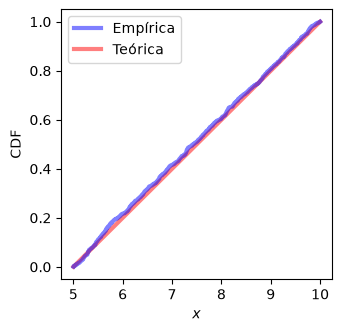

In [4]:
plot_uniform_cdf(5, 5, 1000)

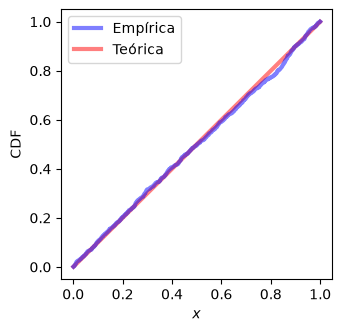

In [5]:
plot_uniform_cdf(0, 1, 1000)

### Parte (*a*)

Repita a análise acima para a distribuição normal. Lembre-se que a distribuição normal possui dois parâmetros: $\mu$ e $\sigma$.

Consulte https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html para gerar números pseudo-aleatórios e para computar a CDF da distribuição normal.

Você deve:
1. Completar a função abaixo para gerar gráficos comparativos entre as CDFs empíricas e teóricas da distribuição normal;
2. Executar seu código, variando os parâmetros da distribuição e número de elementos gerados.

In [6]:
from scipy.stats import norm

In [7]:
def plot_normal_cdf(mu, sigma, n):
  r = norm.rvs(size = n, loc = mu, scale = sigma)

  # plota a CDF empírica dos números gerados
  cdf = ECDF(r)
  plt.plot(cdf.x, cdf.y, linewidth = 3, alpha = 0.5, color = 'blue',
           label = 'Empírica')

  plt.plot(cdf.x, norm.cdf(cdf.x, loc = mu, scale = sigma),
           alpha = 0.5, label = 'Teórica', color = 'red',
           linewidth = 3, zorder = 0);

  # Ajustes de rótulos e tamanho da figura...
  plt.legend(loc = 'best');
  plt.xlabel(r'$x$');
  plt.ylabel(r'CDF');
  plt.gcf().set_size_inches(3.5, 3.5)
  pass

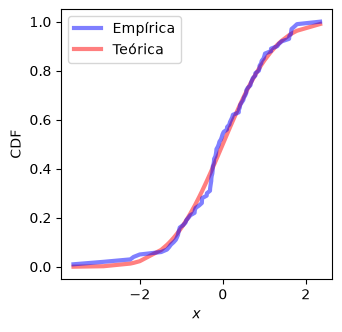

In [8]:
plot_normal_cdf(0, 1, 100)

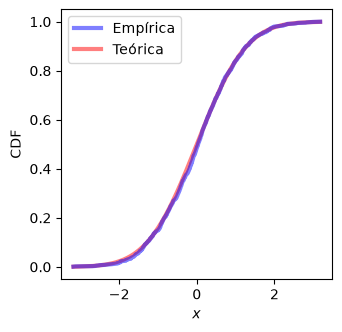

In [9]:
plot_normal_cdf(0, 1, 1000)

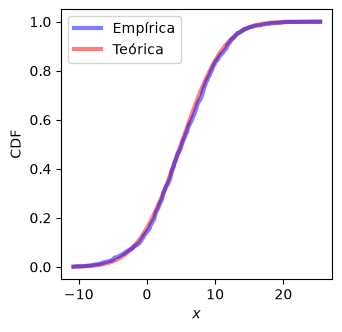

In [10]:
plot_normal_cdf(5, 5, 1000)

### Parte (*b*)

Repita a análise inicial para a distribuição exponencial. Lembre-se, dado um parâmetro $\lambda > 0$, a densidade da distribuição exponencial é:
$$f(x) = \lambda e^{-\lambda x}\text{, } x > 0.$$

Consulte https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html para gerar números pseudo-aleatórios e para computar a CDF da distribuição exponencial.

Você deve:
1. Completar a função abaixo para gerar gráficos comparativos entre as CDFs empíricas e teóricas da distribuição exponencial;
2. Executar seu código, variando os parâmetros da distribuição e número de elementos gerados.

**ATENÇÃO:** Leia com atenção a documentação da biblioteca mencionada para entender como o parâmetro $\lambda$ deve ser fornecido. O $\lambda$ da definição acima não é o mesmo que o `scale` da biblioteca.

In [11]:
from scipy.stats import expon

In [12]:
def plot_exponential_cdf(lambda_, n):
  r = expon.rvs(size = n, scale = 1/lambda_)

  # plota a CDF empírica dos números gerados
  cdf = ECDF(r)
  plt.plot(cdf.x, cdf.y, linewidth = 3, alpha = 0.5, color = 'blue',
           label = 'Empírica')

  plt.plot(cdf.x, expon.cdf(cdf.x, scale = 1/lambda_),
           alpha = 0.5, label = 'Teórica', color = 'red',
           linewidth = 3, zorder = 0);

  # Ajustes de rótulos e tamanho da figura...
  plt.legend(loc = 'best');
  plt.xlabel(r'$x$');
  plt.ylabel(r'CDF');
  plt.gcf().set_size_inches(3.5, 3.5)
  pass

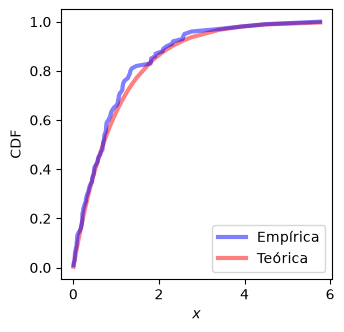

In [13]:
plot_exponential_cdf(1, 100)

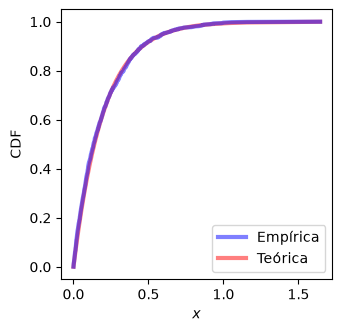

In [14]:
plot_exponential_cdf(5, 1000)


### Parte (*c*)

Agora as coisas ficam mais interessantes...

Repita a análise inicial para a distribuição de pareto. Lembre-se, dado um parâmetro $b > 0$, a densidade da distribuição de pareto é:
$$f(x) = \frac{b}{x^{b+1}}\text{, } x \ge 1.$$

Consulte https://docs.scipy.org/doc/scipy/tutorial/stats/continuous_pareto.html para gerar números pseudo-aleatórios e para computar a CDF da distribuição de pareto.

Você deve:
1. Completar a função abaixo para gerar gráficos comparativos entre as CDFs empíricas e teóricas da distribuição de pareto;
2. Executar seu código, variando os parâmetros da distribuição e número de elementos gerados.

In [15]:
from scipy.stats import pareto

In [16]:
def plot_pareto_cdf(b, n):
  r = pareto.rvs(size = n, b = b)

  # plota a CDF empírica dos números gerados
  cdf = ECDF(r)
  plt.plot(cdf.x, cdf.y, linewidth = 3, alpha = 0.5, color = 'blue',
           label = 'Empírica')

  plt.plot(cdf.x, pareto.cdf(cdf.x, b = b),
           alpha = 0.5, label = 'Teórica', color = 'red',
           linewidth = 3, zorder = 0);

  # Ajustes de rótulos e tamanho da figura...
  plt.legend(loc = 'best');
  plt.xlabel(r'$x$');
  plt.ylabel(r'CDF');
  plt.gcf().set_size_inches(3.5, 3.5)
  pass

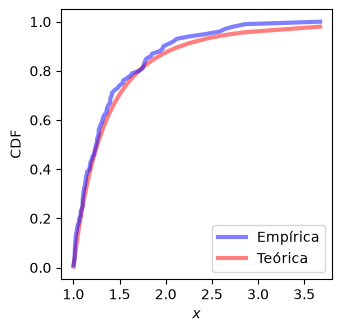

In [17]:
plot_pareto_cdf(3, 100)

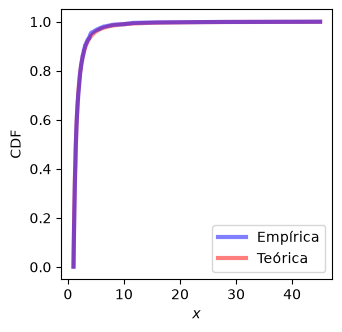

In [18]:
plot_pareto_cdf(2, 1000)

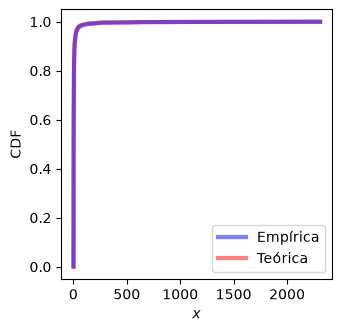

In [19]:
plot_pareto_cdf(1, 1000)

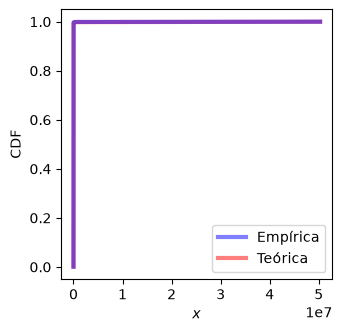

In [20]:
plot_pareto_cdf(0.5, 1000)

Após fazer as figuras, você provavelmente observou que para valores pequenos de $b$, a CDF da distribuição de pareto é bastante difícil de ler, uma vez que fica praticamente "colada" às retas $x = 0$ e $y = 1$.

Esse fenômeno ocorre porque, quando $b$ é pequeno, valores muito grandes (i.e., discrepantes ou *outliers*) têm uma probabilidade não negligível de ocorrerem.

Quando observamos o comportamento das figuras acima, devemos modificar a forma de visualizar a distribuição:
1. Devemos gerar uma figura para a CCDF (*Complementary Cumulative Distribution Function*). A CCDF de um valor $x$ é definida como 1 menos a CDF de $x$.
2. Devemos colocar os eixos $x$ e $y$ em escala logarítmica.

Complete a função abaixo para gerar a figura da forma descrita acima e gere os gráficos para os mesmos casos que testou anteriormente.

In [21]:
def plot_pareto_ccdf(b, n):
  r = pareto.rvs(size = n, b = b)

  # plota 1 - CCDF empírica dos números gerados
  cdf = ECDF(r)
  plt.plot(cdf.x, 1 - cdf.y, linewidth = 3, alpha = 0.5, color = 'blue',
           label = 'Empírica')

  plt.plot(cdf.x, 1 - pareto.cdf(cdf.x, b = b),
           alpha = 0.5, label = 'Teórica', color = 'red',
           linewidth = 3, zorder = 0);

  # Ajustes de rótulos e tamanho da figura...
  plt.legend(loc = 'best');
  plt.xlabel(r'$x$');
  plt.ylabel(r'CCDF');
  plt.xscale('log');
  plt.yscale('log');
  plt.gcf().set_size_inches(3.5, 3.5)
  pass

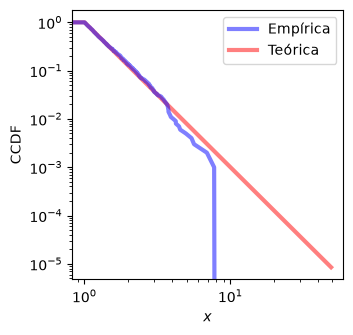

In [22]:
plot_pareto_ccdf(3, 1000)

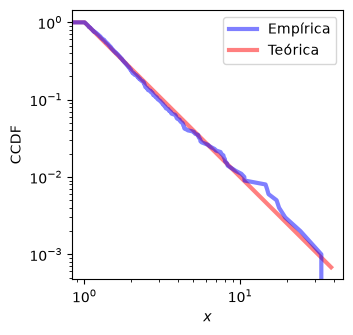

In [23]:
plot_pareto_ccdf(2, 1000)

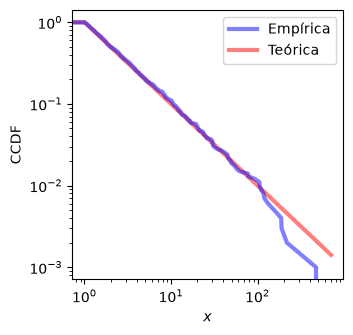

In [24]:
plot_pareto_ccdf(1, 1000)

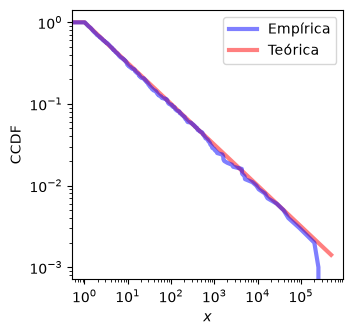

In [25]:
plot_pareto_ccdf(0.5, 1000)

## Questão 2

Esta questão é **obrigatória** apenas para alunos da **pós-graduação**.

O objetivo desta questão é entender o comportamento da **parte (*c*)** da questão anterior.

Você deve ler as duas primeiras seções do artigo https://arxiv.org/pdf/cond-mat/0412004.pdf e fazer um resumo (de no máximo uma página). Certifique-se de incluir no seu resumo, entre outras informações que achar relevantes, o motivo de a CCDF da distribuição de pareto ter a forma que tem quando ambos os eixos estão em escala logarítmica.

## Questão 3

Primeiro, você deve ler os artigos abaixo.
1. [Common pitfalls in statistical analysis: The use of correlation techniques](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5079093/)
2. [Chocolate Consumption, Cognitive Function,
and Nobel Laureates](https://www.nejm.org/doi/full/10.1056/NEJMon1211064)

Resumindo o que foi lido nos artigos, responda as seguintes questões:

1. O que é o coeficiente de correlação?
2. Quando o coeficiente de correlação é útil e quando ele pode ser a ferramenta errada para analisar a relação entre duas variáveis?
3. Qual a diferença entre causalidade e correlação?

**Observação 1:** é esperado que a resposta das três perguntas utilize aproximadamente duas páginas A4.

**Observação 2:** você pode consultar outras fontes para responder as questões acima. No entanto, é esperado que as respostas sejam no contexto do conteúdo dos artigos.

A correlação é uma ferramenta estatística utilizada para medir o grau de associação entre duas variáveis quantitativas. Entretanto, a existência de uma correlação forte e estatisticamente significativa, não é suficiente para demonstrar uma relação causal.

O coeficiente de correlação de Pearson mede a direção e a intensidade da associação linear entre duas variáveis quantitativas. Seu valor varia de −1 a 1. Um valor positivo indica que as variáveis tendem a aumentar juntas, enquanto um valor negativo indica que o aumento de uma está associado à diminuição da outra. Quanto mais próximo o valor absoluto estiver de 1, mais próximos os pontos estarão de uma tendência linear. Um coeficiente próximo de zero indica ausência de relação linear, mas não permite concluir que as variáveis não possuem nenhuma forma de relação.

A necessidade de observar o gráfico de dispersão também aparece na Questão 5 da lista: conjuntos com médias, desvios padrão e correlações praticamente iguais apresentam formas visuais completamente diferentes. Isso demonstra que o coeficiente resume apenas um aspecto dos dados e não substitui sua visualização.

O artigo de Messerli (2012) encontrou uma correlação linear forte entre o consumo de chocolate por habitante e o número de ganhadores do Nobel em diferentes países. Entretanto, esse resultado representa uma associação entre os valores agrupados por país. Não é possível concluir que os indivíduos que consomem mais chocolate sejam aqueles que apresentam melhor desempenho ou recebem o prêmio. Esse tipo de uma associação que tenta inferir a grupos para uma conclusão sobre indivíduos é conhecida como falácia ecológica. Essa é apenas uma das maneira de dizer e manipular discursos com dados reais.

A causalidade implica que determindada variável A altera diretamente na variável B, e como não existe uma comprovação científica que o consumo de chocolate provoque o aumento da inteligência da população ou algo do tipo, o que foi identificado com esse estudo não é uma causalidade mas sim uma correlação.

A correlação é útil para identificar e resumir associações lineares, mas deve ser interpretada juntamente com gráficos, características da amostra e conhecimento sobre a origem dos dados. Uma correlação forte ou estatisticamente significativa não comprova causalidade. Para defender uma relação causal, são necessárias evidências adicionais, como precedência temporal, controle de variáveis de confusão, um mecanismo plausível e um desenho de pesquisa apropriado.

## Questão 4

Obtenha o conjunto de dados disponível no AVA da disciplina para essa questão. O conjunto de dados possui duas colunas: `type` e `score`. Você pode pensar nesses dados como sendo o resultados de medições (`score`) realizadas em um conjunto de objetos que pode ser de três tipos diferentes (`type`).

### Parte (a)

Leia o conjunto de dados e armazene-o em um `DataFrame` do `Pandas`.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_4 = pd.read_csv('dados_questao_4.csv')
df_4.head()

,score,type
0,0.023120,A
1,0.870633,A
2,-0.051788,A
3,0.490284,A
4,-0.296330,A


### Parte (b)

Usando a biblioteca `seaborn`, Faça o *BoxPlot* da variável `score` para todos os objetos, independentemente do tipo.

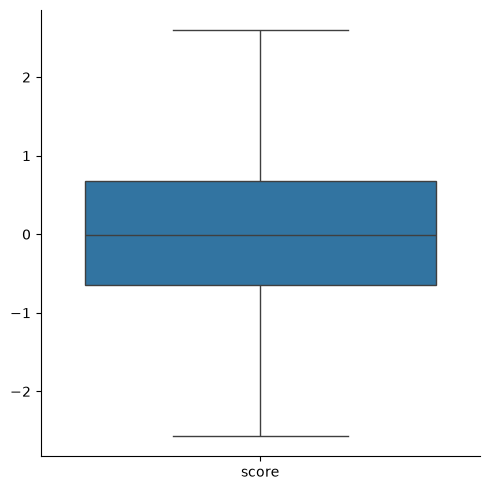

In [27]:
sns.catplot( kind='box', data=df_4)

Agora, faça, em uma mesma figura, os *BoxPlots* para a variável `score` de acordo com a variável `type`. Isto é, um *BoxPlot* da variável `score` para cada valor de `type`. Novamente, use a biblioteca `seaborn`.

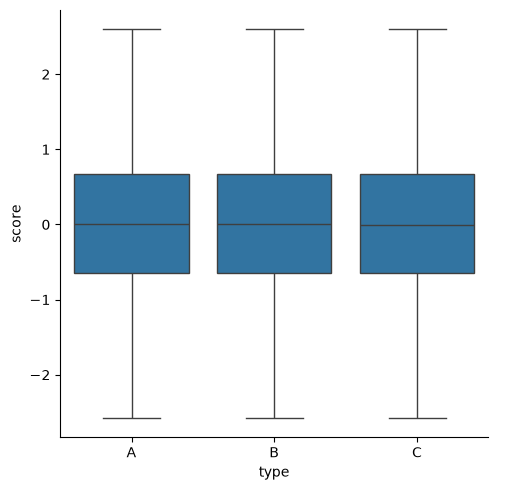

In [28]:
sns.catplot(x='type', y='score', kind='box', data=df_4)

Com base **apenas** nos *BoxPlots*, o que é possível afirmar sobre a dispersão/distribuição dos dados das três variáveis? Você diria que as três distribuições são similares?

Com base nos gráficos BoxPlot a distribuição dos 'types' A, B e C são muito similares e não apresentam outliers, e suas dispersões são practimente iguais.


### Parte (c)

Agora:

1. Repita a Parte (b), mas agora, ao invés de fazer os *BoxPlots*, faça os histogramas.

2. Repita a Parte (b), mas agora, ao invés de fazer os *BoxPlots*, faça as CDFs empíricas (vide Questão 1).

3. Repita a Parte (b), mas agora, ao invés de fazer os *BoxPlots*, faça os gráficos de Violino.



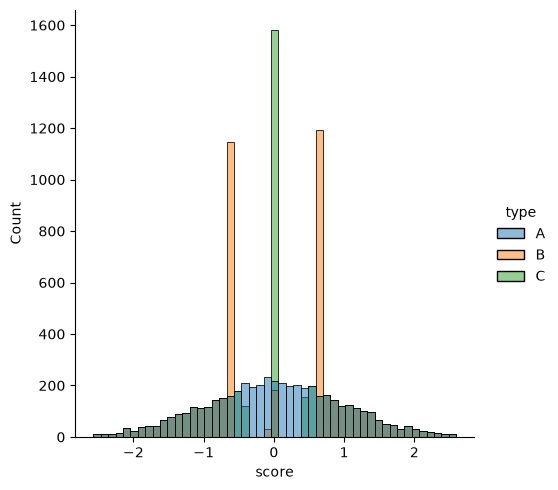

In [29]:
sns.displot(df_4, x="score", hue="type")

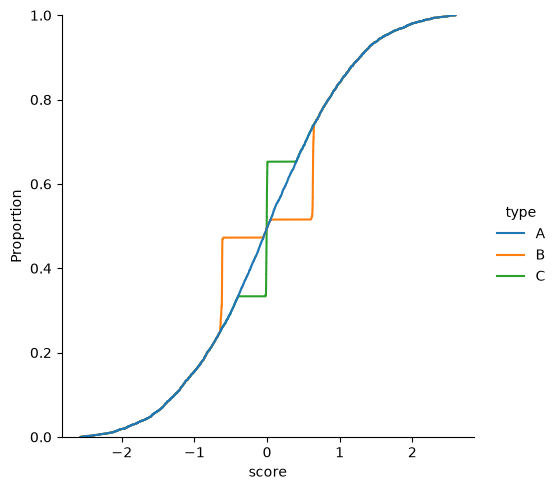

In [30]:
sns.displot(df_4, kind='ecdf',hue="type", x="score")

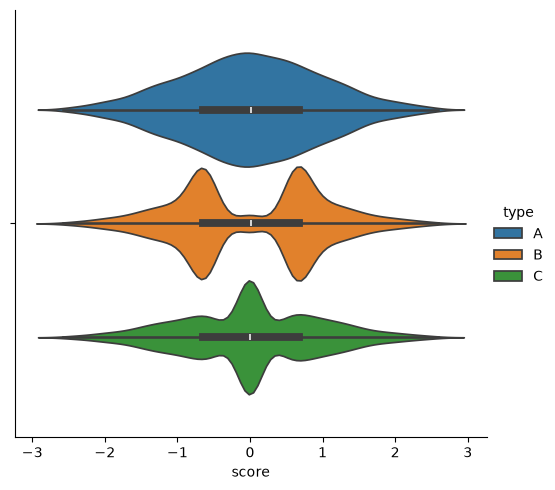

In [31]:
sns.catplot( kind='violin', data=df_4, hue="type", x="score")

Revisitando a conclusão da Parte (b)...

Com base nessas novas figuras, o que é possível dizer sobre a dispersão/distribuição das três variáveis? Você diria que as três distribuições são similares?

Com base nos novos gráficos, pode-se dizer que a distruição do `type A` se aproxima de uma distribuição normal e apresenta formato simétrico. O `type B` apresenta comportamento aparentemente unimodal, com maior concentração de observações em torno de um intervalo. Já o `type C` apresenta comportamento bimodal, com duas regiões de maior concentração. Além disso o histograma e p gráfico de violino revelam que o `type B e C` possuem faixas de valores específicas com alta concetração de observações, evidenciando que cada `type` segue uma distribuicao diferente, mudando a conclusão feita na Parte B da questão. Embora as distribuições tenham formatos diferentes, elas apresentam dispersão global semelhante, pois possuem amplitudes e intervalos de quartis parecidos.

## Questão 5

Ainda no espírito das duas questões anteriores.

Leia o conjunto de dados, disponível no AVA, para a Questão 5 e carregue os dados em um `DataFrame` do `Pandas`. O arquivo contém um conjunto de pontos no plano, ou seja, uma coleção de pares ($x$, $y$).

Na verdade, o arquivo é uma coleção de vários conjuntos de dados. O arquivo possui três colunas:
- `dataset` indica a qual conjunto de dados um ponto pertence
- `x` indica a coordenada $x$ de cada ponto do conjunto
- `y` indica a coordenada $y$ de cada ponto do conjunto



In [32]:
import pandas as pd
df_5 = pd.read_csv('dados_questao_5.csv')
df_5.head()

,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


### Parte (a)

Para cada um dos 13 conjuntos de dados disponível no arquivo, calule e imprima:
1. A média dos valores das colunas `x` e `y`
2. O desvio padrão dos valores das colunas `x` e `y`
3. A correlação linear entre as colunas `x` e `y`

Com base nos valores observados, formule uma hipótese sobre o grau de similaridade entre os diversos conjuntos de dados. Em outras palavras, vocês diriam que eles são similares ou diferentes?

**Observação:** tente modularizar seu código e utilizar os recursos do `Pandas`, por exemplo, `groupby`.

In [54]:
#df_5.groupby("dataset").describe().round(2)
grupos = df_5.groupby("dataset")

resumo = grupos.agg(
    media_x=("x", "mean"),
    desvio_x=("x", "std"),
    media_y=("y", "mean"),
    desvio_y=("y", "std")
)

resumo["correlacao_xy"] = grupos[["x", "y"]].apply(lambda grupo: grupo["x"].corr(grupo["y"]))

display(resumo.round(3))

,media_x,desvio_x,media_y,desvio_y,correlacao_xy
dataset,,,,,
away,54.266,16.770,47.835,26.940,-0.064
bullseye,54.269,16.769,47.831,26.936,-0.069
circle,54.267,16.760,47.838,26.930,-0.068
dino,54.263,16.765,47.832,26.935,-0.064
dots,54.260,16.768,47.840,26.930,-0.060
h_lines,54.261,16.766,47.830,26.940,-0.062
high_lines,54.269,16.767,47.835,26.940,-0.069
slant_down,54.268,16.767,47.836,26.936,-0.069
slant_up,54.266,16.769,47.831,26.939,-0.069


De acordo com as informações de médias, desvios e correlação, os dados dos grupos de dataset são similares e possuem comportamento semelhante, apresentando uma diferença de valores na maioria das vezes apenas na terceira casa decimal. Todos dos datasets apresentam uma correlação liner fraca.

### Parte (b)

Agora, vamos testar a hipótese estabelecida no item anterior. Faça um gráfico, para cada um dos 13 conjuntos de dados, marcando os pontos de cada conjunto no plano.

Com base nos gráficos, o que pode ser dito sobre o grau de similaridade entre os diversos conjuntos de dados? Em outras palavras, vocês diriam que eles são similares ou diferentes?

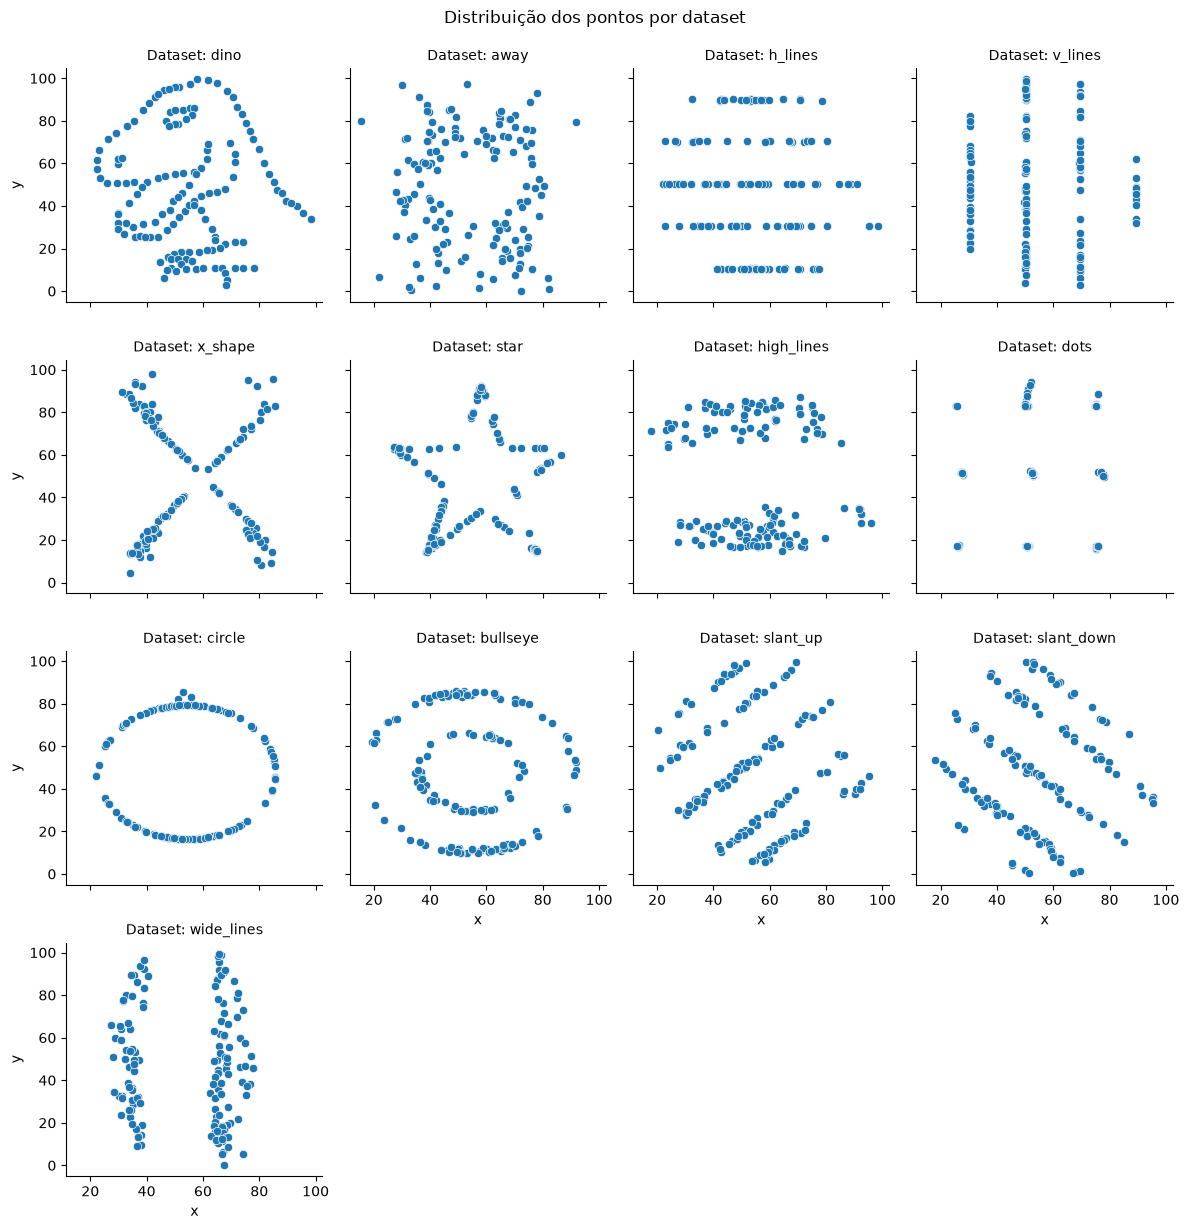

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.relplot(
    data=df_5,
    x="x",
    y="y",
    col="dataset",
    col_wrap=4,
    kind="scatter",
    height=3,
    aspect=1,
    facet_kws={
        "sharex": True,
        "sharey": True
    }
)

g.set_titles("Dataset: {col_name}")
g.set_axis_labels("x", "y")
g.figure.suptitle("Distribuição dos pontos por dataset", y=1.02)

plt.show()

Observando os gráficos, pode-se perceber que cada dataset possui uma forma e dispersão de observações distinta, alguns apresentam figuras como um dinossaouro e uma estrela e outros são formas, linhas e pontos. Portanto a hipótese anterior não é confirmada, e comportamento dos valores (numéricos) de média, desvio e correlação são completamente diferentes do comportamento (visual) dos pontos num plano. 

## Referências (Spoiler Alert!)

Os dados de algumas questões foram obtidos em https://www.research.autodesk.com/publications/same-stats-different-graphs/. Para não estragar a surpresa, sugiro consultar essa referência apenas após tentar resolver as questões. De toda forma, as respostas das perguntas não estão contidas na página citada.

## Leitura Recomendada (não vale pontos e não é necessário entregar)

Quer entender um pouco mais sobre a **história** e o **início** das ferramentas para processamento de grandes bases de dados?

1. MapReduce (2004) https://www.cs.princeton.edu/courses/archive/fall13/cos518/papers/mapreduce.pdf

2. HDFS (2007) https://www.cs.stolaf.edu/docs/hadoop/hdfs_design.pdf

3. Spark (2012) https://www.usenix.org/system/files/conference/nsdi12/nsdi12-final138.pdf